In [13]:
import arviz as az
import bambi as bmb
import polars as  pl
import numpy as np
import pandas as pd

from matplotlib import pyplot as plt

from kidney.contrasts import get_t_groups, get_overall_effects, get_gtyp_given_sex_age, get_sex_given_gtyp_age
from kidney.paths import RESULTS_DIR_NEW, PREPARED_FILES_NEW, PLOT_DIR_NEW
from kidney.plotting import forestplot_oz, plot_ppc, set_symmetric_xlim
from kidney.sign_probs import get_sign_probs, get_signif

In [14]:
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['font.family'] = 'Arial'
az.rcParams["data.load"] = "eager"

In [15]:
idata_vehicle = az.from_netcdf(RESULTS_DIR_NEW / "idata_baseline_power_vehicle_cb.nc")
idata_empa = az.from_netcdf(RESULTS_DIR_NEW / "idata_baseline_power_empa_cb.nc")

In [16]:
print("Vehicle:")
display(az.summary(idata_vehicle, var_names=["~mu", "~1|rat", "~sigma"]))
print("Empa:")
display(az.summary(idata_empa, var_names=["~mu", "~1|rat", "~sigma"]))

Vehicle:


,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
Intercept,2.642,0.368,1.919,3.325,0.011,0.008,1066.0,1477.0,1.0
gtyp[fa/fa],0.476,0.566,-0.628,1.507,0.016,0.012,1188.0,1601.0,1.0
age[Young],0.139,0.569,-0.885,1.250,0.017,0.012,1147.0,1469.0,1.0
sex[M],-0.206,0.539,-1.216,0.805,0.017,0.012,1010.0,1351.0,1.0
"gtyp:age[fa/fa, Young]",-0.109,0.782,-1.528,1.366,0.023,0.018,1121.0,1387.0,1.0
"gtyp:sex[fa/fa, M]",-1.190,0.737,-2.533,0.209,0.022,0.017,1063.0,1381.0,1.0
1|rat_sigma,1.060,0.149,0.788,1.339,0.005,0.003,744.0,1452.0,1.0


Empa:


,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
Intercept,2.154,0.372,1.462,2.843,0.013,0.008,807.0,1095.0,1.01
gtyp[fa/fa],0.402,0.566,-0.643,1.479,0.018,0.014,961.0,1128.0,1.00
age[Young],-0.329,0.525,-1.370,0.595,0.016,0.010,1087.0,1569.0,1.00
sex[M],0.049,0.519,-0.924,1.005,0.017,0.011,937.0,1425.0,1.00
"gtyp:age[fa/fa, Young]",0.622,0.710,-0.658,1.974,0.023,0.013,942.0,1474.0,1.01
"gtyp:sex[fa/fa, M]",-1.586,0.734,-2.856,-0.139,0.023,0.015,1027.0,1652.0,1.00
1|rat_sigma,1.016,0.143,0.759,1.272,0.005,0.004,893.0,1326.0,1.00


In [17]:
msts_vehicle = pl.read_csv(PREPARED_FILES_NEW["baseline_power_vehicle_cb"])
msts_empa = pl.read_csv(PREPARED_FILES_NEW["baseline_power_empa_cb"])

## Posterior predictive checks

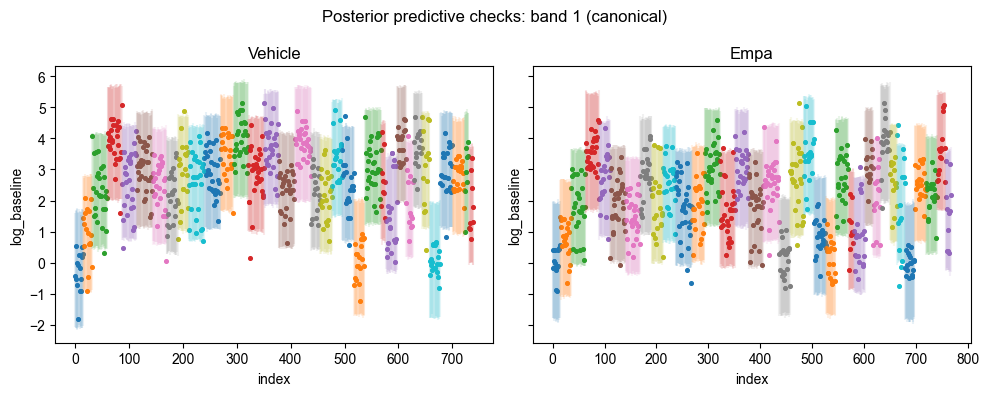

In [18]:
PLOT_DIR_NEW.mkdir(parents=True, exist_ok=True)
f, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for ax, idata, name, msts in zip(
    axes,
    (idata_vehicle, idata_empa),
    ("vehicle", "empa"),
    (msts_vehicle, msts_empa),
):
    ax = plot_ppc(ax, idata, msts, ycol="log_baseline", groupcol="rat")
    ax.set_title(name.capitalize())
    legend = ax.get_legend()
    if legend is not None:
        legend.remove()

f.suptitle("Posterior predictive checks: band 1 (canonical)")
f.tight_layout()
f.savefig(PLOT_DIR_NEW / "ppc_baseline_power-canon-band.png", bbox_inches="tight", dpi=200)

Each dot is a vessel, sorted by rat; lines are 1%–99% posterior predictive intervals. The dataset now contains only canonical-band baseline power, so there is no band-specific subdivision.

## Effects

The model is `log_baseline ~ (1|rat) + gtyp + age + sex + gtyp:age + gtyp:sex`, with a single residual standard deviation. Contrasts follow the brief. The overall effect of a factor is averaged with equal weights over the levels of the other factors, e.g. the overall gtyp effect is the mean of fa/fa − fa/+ over the four age/sex groups. The gtyp effect given sex is averaged over age, and vice versa. SP is the posterior probability that the contrast is positive; lines are 95% intervals.
The combined plot replaces the overall sex effect with male − female contrasts within `fa/fa` and `fa/+`, averaged over age. Sex-given-age contrasts are excluded.

In [19]:
def plot_effects(ts_vehicle, ts_empa, figsize):
    f, axes = plt.subplots(1, 2, figsize=figsize)
    for ax, ts, tle in zip(axes, (ts_vehicle, ts_empa), ("Vehicle", "Empa")):
        ax = forestplot_oz(ax, ts, xlabel="Test statistic\n(baseline power)", sign_probs=True)
        set_symmetric_xlim(ax, ts, pad=1.8)
        ax.set_title(tle)
        ax.spines[['top', 'right', 'left']].set_visible(False)
    axes[1].set_yticks([], [])
    return f, axes


t_groups_vehicle, t_groups_empa = (get_t_groups(idata) for idata in (idata_vehicle, idata_empa))
overall_ts_vehicle, overall_ts_empa = (
    get_overall_effects(t_groups)
    for t_groups in (t_groups_vehicle, t_groups_empa)
)
gtyp_ts_vehicle, gtyp_ts_empa = (get_gtyp_given_sex_age(t_groups) for t_groups in (t_groups_vehicle, t_groups_empa))
sex_ts_vehicle, sex_ts_empa = (
    get_sex_given_gtyp_age(t_groups)
    for t_groups in (t_groups_vehicle, t_groups_empa)
)

# Replace the overall sex contrast with sex effects within each genotype.
# Exclude the sex-given-age contrasts.
plot_ts_vehicle = {
    **{k: v for k, v in overall_ts_vehicle.items() if k != "male - female"},
    **{k: v for k, v in sex_ts_vehicle.items() if k in ("male - female, fa/fa", "male - female, fa/+")},
}
plot_ts_empa = {
    **{k: v for k, v in overall_ts_empa.items() if k != "male - female"},
    **{k: v for k, v in sex_ts_empa.items() if k in ("male - female, fa/fa", "male - female, fa/+")},
}

### Overall genotype and age effects; sex effects given genotype

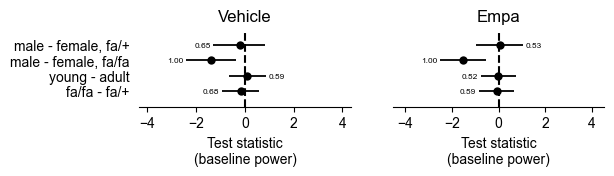

In [25]:
f, axes = plot_effects(plot_ts_vehicle, plot_ts_empa, figsize=(6, 1))
f.savefig(PLOT_DIR_NEW / "ts_baseline_power_overall_and_sg-canon.pdf", bbox_inches="tight", dpi=200)

### Effect of gtyp given sex and given age

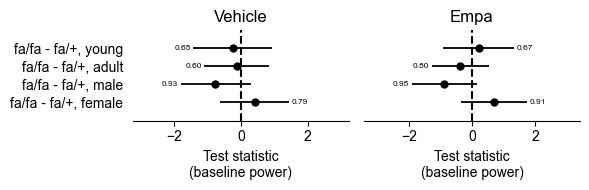

In [23]:
f, axes = plot_effects(gtyp_ts_vehicle, gtyp_ts_empa, figsize=(6, 2))
f.tight_layout()
# f.savefig(PLOT_DIR_NEW / "ts_baseline_power_gtyp_given_sex_age-canon.png", bbox_inches="tight", dpi=200)

## Show sign probabilities in tables

In [24]:
sp_all = pd.concat(
    objs=[
        pd.DataFrame({
            "vehicle": get_sign_probs(ts_vehicle),
            "vehicle_signif": {k: get_signif(v) for k, v in get_sign_probs(ts_vehicle).items()},
            "empa": get_sign_probs(ts_empa),
            "empa_signif": {k: get_signif(v) for k, v in get_sign_probs(ts_empa).items()},
        })
        for ts_vehicle, ts_empa in (
            (plot_ts_vehicle, plot_ts_empa),
            (gtyp_ts_vehicle, gtyp_ts_empa),
        )
    ],
    keys=("overall + sex given gtyp", "gtyp given sex/age"),
    names=("contrast", "group"),
)
sp_all

vehicle vehicle_signif  \
contrast                 group                                          
overall + sex given gtyp fa/fa - fa/+          0.31800                  
                         young - adult         0.58825                  
                         male - female, fa/fa  0.00425              *   
                         male - female, fa/+   0.34750                  
gtyp given sex/age       fa/fa - fa/+, female  0.79225                  
                         fa/fa - fa/+, male    0.07025                  
                         fa/fa - fa/+, adult   0.39900                  
                         fa/fa - fa/+, young   0.35375                  

                                                  empa empa_signif  
contrast                 group                                      
overall + sex given gtyp fa/fa - fa/+          0.40850              
                         young - adult         0.48400              
                         male - female, fa/fa  0.00275           *  
                         male - female, fa/+   0.53350              
gtyp given sex/age       fa/fa - fa/+, female  0.91250              
                         fa/fa - fa/+, male    0.05325              
                         fa/fa - fa/+, adult   0.19700              
                         fa/fa - fa/+, young   0.66875